# Shallow circuits for small-molecule energies with GCiM and QFD

ADAPT-GCiM and quantum filter diagonalization (QFD) estimate a molecule's ground-state energy as the lowest eigenvalue of a small projected problem $Hc=ESc$, whose matrix elements come from circuits that prepare pairs of basis states. Each generator or time step in a basis state makes its circuits deeper. This notebook shows on H₂ and on a stretched H₄ chain which inputs change only the measurement cost, which change the basis and with it the energy, and how far each energy lies from the exact (FCI) value. It also plans a 26-qubit model without running it.

Install with `python -m pip install "nwqlib[aer,notebook,chemistry]"`. The notebook simulates circuits of at most 9 qubits and runs in about 40 s on an Apple M3 Max with 36 GiB of memory (Python 3.12.14, Qiskit 2.6.0, Aer 0.18.0).

> **How to read this notebook.** The next cells compute the H₂ energy with QFD and show it with its cost.
>
> - Section 1: measurement choices on H₂, with the same basis and the same energy
> - Section 2: shorter generator products and fewer time steps on H₄, which change the basis
> - Section 3: a 26-qubit model, planned and not run
> - Section 4: your own Hamiltonian, and one refusal

In [1]:
from time import perf_counter

from nwqlib import solve
from nwqlib.algorithms import QFD
from nwqlib.algorithms.gcim import build_gcim_chemistry_problem
from nwqlib.algorithms.qfd import chemistry_evolution_terms
from nwqlib.problems import ingest_occupation

started = perf_counter()
# H2 at 0.74 Å in the STO-3G basis on 4 qubits. CASCI over both orbitals is the exact (FCI) energy.
h2 = build_gcim_chemistry_problem("H 0 0 0; H 0 0 0.74", basis="sto-3g", active_space=(2, 2),
                                  reference_methods=("casci",))
problem = h2.eigenproblem()
reference = ingest_occupation(tuple(h2.reference_occupations), num_qubits=h2.num_qubits)  # Hartree–Fock state
terms, diagnostics = chemistry_evolution_terms(h2)  # fermionic generator of the step V, from the same integrals
method = QFD(initial_state=reference, time_step=0.5, powers=(0, 1, 2), evolution="fermionic_blocks",
             evolution_terms=terms, evolution_diagnostics=diagnostics)
result = solve(problem, method=method, seed=7, progress=False)  # six pair circuits on Aer, exact readout
seconds = perf_counter() - started
E_FCI = h2.reference_panel["e_casci"]  # hartree

In [2]:
# Display helpers for tables, the figure and the result card, and the compiled CX count of prepared circuits.
# They read the records passed to them and run no solve.
from html import escape

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display

from nwqlib import plan, prepare

plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
MILLIHARTREE = 1e3          # hartree to millihartree
CHEMICAL_ACCURACY = 1.6e-3  # hartree, about 1 kcal/mol
# Qiskit's compiler with CX and one-qubit gates, at optimization level 0 and without routing.
LEVEL_0 = {"basis_gates": ["cx", "u"], "optimization_level": 0, "seed_transpiler": 7, "approximation_degree": 1.0}


def format_value(value, digits=3):
    """Round only the display to ``digits`` significant digits. Calculations keep full precision."""
    if value is None:
        return "not available"
    if isinstance(value, (bool, np.bool_, str)):
        return str(value)
    if isinstance(value, (int, np.integer)) or isinstance(value, (float, np.floating)) and float(value).is_integer():
        return f"{int(value):,}"
    if isinstance(value, (float, np.floating)):
        return f"{value:.{digits}g}"
    if isinstance(value, (tuple, list)):
        return ", ".join(format_value(item, digits) for item in value)
    return str(value)


def show_table(rows, headers, *, digits=3):
    """Display rows of computed quantities as a table."""
    body = "".join("<tr>" + "".join('<td style="text-align:left">' + escape(format_value(value, digits)) + "</td>"
                                    for value in row) + "</tr>" for row in rows)
    display(HTML("<table><thead><tr>" + "".join("<th>" + escape(label) + "</th>" for label in headers)
                 + "</tr></thead><tbody>" + body + "</tbody></table>"))


def amount(estimate_record, metric, location=None):
    """The value of one quantity of a resource estimate, or None when the estimate leaves it unknown."""
    quantity = (estimate_record.quantity(metric) if location is None
                else estimate_record.quantity(metric, location=location))
    if quantity.fact.availability != "concrete":
        return None
    value = quantity.fact.value
    return value.numerator if value.kind == "rational" else value.value


def compiled_cx(planned):
    """CX gates of every circuit of a Plan, compiled with LEVEL_0, in the order of its setting names."""
    prepared = prepare(planned, settings="all", progress=False)  # builds every circuit, runs nothing
    with prepared.run:
        return [prepared.inspect_resources(index=index, transpile_options=LEVEL_0)["operations"].get("cx", 0)
                for index in range(len(prepared.setting_names))], list(prepared.setting_names)


def show_card(result, exact, h2, names, cx_prefix, cx_controlled, sampled_settings, seconds):
    """Show the result card: the energy against FCI, the quantum and classical cost, the figure and the steps."""
    error = result.eigenvalue - exact
    display(HTML(
        f"<p><strong>Result.</strong> QFD with the powers 0, 1 and 2 of one second-order step V of time 0.5/Ha "
        f"gives {result.eigenvalue:.6f} Ha, {abs(error):.1e} Ha from the exact (FCI) energy, a difference at "
        f"rounding level, because these three basis states span the H₂ ground state. The Hartree–Fock reference "
        f"lies {MILLIHARTREE * (result.reference_energy - exact):.3g} mHa above it. Execution: Aer's statevector "
        f"simulator with exact readout, which samples no shots. Output: <code>result.eigenvalue</code>, the "
        f"energy in hartree.</p>"
        f"<p><strong>Cost.</strong> Quantum: {h2.num_qubits + 1} qubits per circuit, the system and one ancilla, "
        f"{len(names)} pair circuits, at most {max(cx_prefix):,} CX gates per circuit and {sum(cx_prefix):,} in "
        f"all, compiled at optimization level 0 without routing. With finite shots the same basis needs "
        f"{sampled_settings} measurement settings (Section 1). Classical: {seconds:.1f} s on this computer, "
        f"chemistry setup included.</p>"))
    fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
    x = np.arange(len(names))
    ax.bar(x - 0.2, cx_prefix, width=0.4, color="#0072B2", label='pair_preparation="prefix", the default')
    ax.bar(x + 0.2, cx_controlled, width=0.4, color="#E69F00", label='pair_preparation="controlled"')
    ax.set(xticks=x, xticklabels=[name.replace("pair_", "pair ").replace("_", ",") for name in names],
           ylabel="CX gates per circuit", title="H₂ QFD pair circuits, compiled at optimization level 0")
    ax.legend(fontsize=8, loc="upper left")
    plt.show()
    steps = (
        f"Ran Hartree–Fock with PySCF, mapped the electronic Hamiltonian to {len(h2.hamiltonian)} Pauli strings on "
        f"{h2.num_qubits} qubits with the Jordan–Wigner transformation and built, from the same integrals, a "
        f"fermionic generator split into {len(result.plan.reconstruction.step_blocks.array) // 2} number-conserving "
        f"blocks.",
        "Built one second-order step V from those blocks and prepared each pair of basis states V^j|HF⟩, V^k|HF⟩ "
        "as one joint state with an ancilla, running the smaller power once without control.",
        "Read the overlaps and Hamiltonian matrix elements of the six pairs from the final states, removed the "
        "overlap directions at or below the cutoff 1e-12 and solved Hc = ESc.",
    )
    display(HTML("<p><strong>What NWQLib did for you.</strong></p><ol>"
                 + "".join(f"<li>{step}</li>" for step in steps) + "</ol>"))

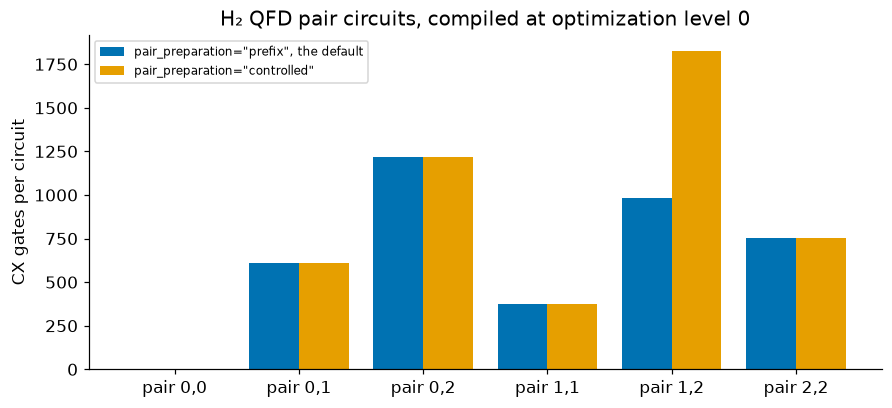

In [3]:
from nwqlib.algorithms import PencilAcquisition

controlled_method = QFD(initial_state=reference, time_step=0.5, powers=(0, 1, 2), evolution="fermionic_blocks",
                        evolution_terms=terms, evolution_diagnostics=diagnostics,
                        acquisition=PencilAcquisition(pair_preparation="controlled"))
controlled = solve(problem, method=controlled_method, seed=7, progress=False)
cx_prefix, pair_names = compiled_cx(result.plan)
cx_controlled, _ = compiled_cx(controlled.plan)
qfd_sampled = plan(problem, method=method, shots=4096, seed=7)  # planned with finite shots, not run
show_card(result, E_FCI, h2, pair_names, cx_prefix, cx_controlled, len(qfd_sampled.experiments), seconds)

**Your own problem.** Section 4 has a template cell for a Pauli sum you supply.

## 1. Measurement choices on H₂

**Which inputs change only how $H$ and $S$ are measured, and what do they cost?** These choices keep the basis, so with exact readout they give the same energy. The card cell compiled the 12 circuits of the table below, and the cells of this section run three finite-shot solves, in a few seconds.

**Pair preparation.** Each off-diagonal pair $j<k$ prepares the joint state $(|0\rangle|\phi_j\rangle+|1\rangle|\phi_k\rangle)/\sqrt2$ of one ancilla and the system. With the default `pair_preparation="prefix"`, QFD runs the reference and the smaller power of V once without control and controls only the remaining power difference, which is valid because powers of one V commute. `pair_preparation="controlled"` controls both complete preparations. The figure above compares the compiled circuits, and the table repeats the counts with both energies.

In [4]:
show_table([(name, prefix, controlled_cx) for name, prefix, controlled_cx in zip(pair_names, cx_prefix, cx_controlled)]
           + [("All six circuits", sum(cx_prefix), sum(cx_controlled)),
              ("Energy error against FCI [Ha]", result.eigenvalue - E_FCI, controlled.eigenvalue - E_FCI)],
           headers=("Pair circuit", 'CX, "prefix"', 'CX, "controlled"'))

Pair circuit,"CX, ""prefix""","CX, ""controlled"""
pair_0_0,0,0
pair_0_1,608,612
pair_0_2,"1,216","1,220"
pair_1_1,376,376
pair_1_2,984,"1,828"
pair_2_2,752,752
All six circuits,"3,936","4,788"
Energy error against FCI [Ha],1.35e-14,1.38e-14


The two diagonal pairs (1, 1) and (2, 2) prepare one state each without control, so their counts agree. The pair (1, 2) differs most. The prefix preparation applies V once without control and one controlled V, while the controlled preparation applies a controlled V and a controlled $V^2$, each after a controlled reference preparation. Pairs with the reference save only the CX gates that control the reference's X gates. These counts precede routing to a device, and another Qiskit version can give other counts.

**Real-only measurement.** With `shots=N`, each setting measures one group of qubit-wise commuting Pauli terms of $H$ in their common eigenbasis, together with the ancilla in the X basis for real parts or the Y basis for imaginary parts. The H₂ Hamiltonian's 14 nonidentity terms form the $G$ groups listed below. When the library proves from the inputs that $H$ and every basis state are real, the default `PencilAcquisition(quadratures="auto")` leaves out the Y settings, so $b$ basis states need $b(b+1)G/2$ settings instead of $b^2G$ ([GCiM guide](../docs/algorithms/gcim.md#how-matrix-elements-are-obtained)). QFD always measures both parts, because the library has no proof that its time-evolved states are real.

The cell compares FixedGCIM on the basis of the Hartree–Fock determinant $|0011\rangle$ and the doubly excited $|1100\rangle$, which spans the H₂ ground state, with the QFD basis above, all at 4096 shots per setting on Aer's counts simulator.

In [5]:
from nwqlib import estimate
from nwqlib.algorithms import FixedGCIM

doubly_excited = tuple(1 - occupied for occupied in h2.reference_occupations)
determinants = (reference, ingest_occupation(doubly_excited, num_qubits=h2.num_qubits))
fixed_exact = solve(problem, method=FixedGCIM(basis=determinants), seed=7, progress=False)
measured = {}
for label, chosen in (('FixedGCIM, quadratures="auto"', FixedGCIM(basis=determinants)),
                      ('FixedGCIM, quadratures="complex"',
                       FixedGCIM(basis=determinants, acquisition=PencilAcquisition(quadratures="complex"))),
                      ("QFD, powers 0, 1, 2", method)):
    planned = plan(problem, method=chosen, shots=4096, seed=7)
    measured[label] = (planned, solve(planned, progress=False))
groups = [group.basis for group in measured['FixedGCIM, quadratures="auto"'][0].reconstruction.groups]
show_table([(label, len(planned.experiments), amount(estimate(planned), "shots"),
             MILLIHARTREE * (sampled.eigenvalue - E_FCI)) for label, (planned, sampled) in measured.items()],
           headers=("Measurement", "Settings", "Shots", "Error against FCI [mHa], one run, seed 7"))
print(f"G = {len(groups)} groups, measured in the bases {', '.join(groups)} (qubit 0 rightmost). "
      f"Exact readout of the two determinants: error {fixed_exact.eigenvalue - E_FCI:.1e} Ha.")

Measurement,Settings,Shots,"Error against FCI [mHa], one run, seed 7"
"FixedGCIM, quadratures=""auto""",15,"61,440",0.366
"FixedGCIM, quadratures=""complex""",20,"81,920",0.321
"QFD, powers 0, 1, 2",45,"184,320",0.349


G = 5 groups, measured in the bases ZZZZ, XXYY, XYYX, YXXY, YYXX (qubit 0 rightmost). Exact readout of the two determinants: error 8.9e-16 Ha.


Real-only measurement halves only the off-diagonal settings, from $2G$ to $G$ for the one off-diagonal pair, and the QFD basis of three states needs $3^2G$ settings. The errors come from shot noise and change with the seed. Real-only measurement assumes ideal real states, so on a device it does not show that the imaginary parts vanish.

## 2. Shorter generator products and fewer time steps on H₄

**What do shallower bases give on a strongly correlated molecule?** Four hydrogen atoms 2 Å apart, the chain of the [eigenvalue notebook](gcim_lanczos_qpe_eigenvalue_intro.ipynb), on 8 qubits. These choices change the basis, so they change the energy, and each row is a different approximation. The cell runs three ADAPT solves with exact classical evaluation and two QFD solves as 9-qubit circuits with exact readout, and prints its run time.

**ADAPT-GCiM.** The default growth adds the product of all selected generators, so after eight iterations its longest basis state applies eight generator exponentials $e^{\theta A_k}$. `basis_growth=BoundedRitzGrowth(max_chain_length=L)` instead grows the basis by one product of at most $L$ generators per round, chosen by a score from the current Ritz pair ([Bounded Ritz growth](../docs/algorithms/gcim.md#bounded-ritz-growth)). With `max_iterations=15` it reaches the same largest basis of 16 states. Each examined extension that the round evaluates needs $b+1$ new pairs of basis states, which is the selection cost the table counts.

**QFD.** The basis is the powers of one step V of time $\tau=0.5$/Ha. The deepest circuit applies V as many times as the largest power.

In [6]:
from math import pi

from nwqlib.algorithms.gcim import BoundedRitzGrowth

section_started = perf_counter()
h4 = build_gcim_chemistry_problem("; ".join(f"H 0 0 {2.0 * index}" for index in range(4)), basis="sto-3g",
                                  active_space=(4, 4), reference_methods=("casci",))
h4_problem = h4.eigenproblem()
E4_FCI = h4.reference_panel["e_casci"]  # hartree
growths = {"default growth, 8 iterations": (None, 8),
           "BoundedRitzGrowth(max_chain_length=2), 15 rounds": (BoundedRitzGrowth(max_chain_length=2), 15),
           "BoundedRitzGrowth(max_chain_length=3), 15 rounds": (BoundedRitzGrowth(max_chain_length=3), 15)}
adapt_runs = {label: solve(h4_problem, method=h4.adapt_method(pool="spin_adapted_sd", theta=pi / 4,
                                                              max_iterations=rounds, basis_growth=growth),
                           execution="classical", seed=7, progress=False)
              for label, (growth, rounds) in growths.items()}


def adapt_pairs(run):
    """Pairs of basis states whose matrix elements the run obtained: b(b+1)/2 for the default growth, and for
    bounded growth the reference's diagonal pair plus b + 1 for every evaluated extension of a round on b states."""
    if run.plan.method.basis_growth is None:
        return len(run.pencil.overlap) * (len(run.pencil.overlap) + 1) // 2
    return 1 + sum((index + 2) * sum(c.eta is not None for c in row.candidates)
                   for index, row in enumerate(run.history))


def longest_chain(run):
    """Generator exponentials in the longest basis state."""
    if run.plan.method.basis_growth is None:
        return run.history[-1].iteration  # the product of all selected generators
    return max(len(chain) for chain in run.basis)


h4_reference = ingest_occupation(tuple(h4.reference_occupations), num_qubits=h4.num_qubits)
h4_terms, h4_diagnostics = chemistry_evolution_terms(h4)
qfd_runs = {f"QFD, powers {', '.join(map(str, powers))}": solve(
    h4_problem, method=QFD(initial_state=h4_reference, time_step=0.5, powers=powers, evolution="fermionic_blocks",
                           evolution_terms=h4_terms, evolution_diagnostics=h4_diagnostics), seed=7, progress=False)
    for powers in ((0, 1, 2), (0, 1, 2, 3, 4))}
show_table([(label, len(run.pencil.overlap), longest_chain(run), adapt_pairs(run), run.stop_reason,
             MILLIHARTREE * (run.eigenvalue - E4_FCI)) for label, run in adapt_runs.items()]
           + [(label, len(run.pencil.overlap), max(run.plan.method.powers), len(run.pencil.overlap)
               * (len(run.pencil.overlap) + 1) // 2, "none, fixed powers", MILLIHARTREE * (run.eigenvalue - E4_FCI))
              for label, run in qfd_runs.items()],
           headers=("Basis", "Basis states", "Longest state: generators or powers of V", "Pairs of basis states",
                    "Stop reason", "Error against FCI [mHa], exact evaluation"))
print(f"{len(adapt_runs) + len(qfd_runs)} solves and the H₄ chemistry setup in {perf_counter() - section_started:.0f} s.")

Basis,Basis states,Longest state: generators or powers of V,Pairs of basis states,Stop reason,"Error against FCI [mHa], exact evaluation"
"default growth, 8 iterations",16,8,136,max_iterations,-1.39e-09
"BoundedRitzGrowth(max_chain_length=2), 15 rounds",15,2,541,no_admissible_candidate,9.06e-11
"BoundedRitzGrowth(max_chain_length=3), 15 rounds",16,3,541,max_iterations,46.4
"QFD, powers 0, 1, 2",3,2,6,"none, fixed powers",2.71
"QFD, powers 0, 1, 2, 3, 4",5,4,15,"none, fixed powers",1.15


5 solves and the H₄ chemistry setup in 28 s.


Products of at most two generators reach the FCI energy at rounding level with 15 basis states, against the eight-generator products of the default growth. Growth stopped with `no_admissible_candidate` because no extension that the next round evaluated had both a finite score and a squared norm above `independence_cutoff` for its part outside the kept overlap subspace. With $L=3$ the rounds added other products and stopped at `max_iterations` about 46 mHa above FCI, so a larger $L$ allows longer products but does not by itself lower the energy after a given number of rounds. Bounded growth also obtained more pairs of basis states than the default growth, because it evaluates several extensions per round.

QFD with three powers lies about 2.7 mHa above FCI, and five powers bring it to about 1.2 mHa, within chemical accuracy (1.6 mHa), with 15 pairs and circuits up to $V^4$. How many powers reach a given accuracy depends on the molecule and the time step.

Every value comes from exact matrix elements, so each is a Rayleigh–Ritz value at or above the exact energy, up to rounding. The FCI energy is exact only within the STO-3G basis. With shots, `BoundedRitzGrowth` scores only extensions that pass a sampled eligibility rule, and `basis_depth_limit` bounds the CX count of every basis state with quantum execution ([Bounded Ritz growth](../docs/algorithms/gcim.md#bounded-ritz-growth)).

## 3. A 26-qubit model, planned and not run

**What would the measurement cost at 26 qubits?** The cell plans and estimates without preparing or simulating any circuit, in under a second, and forms no state vector.

The model has $A=-0.5\sum_kZ_k+0.25\sum_kZ_kZ_{k+1}+0.1\sum_{k\,\rm even}X_kX_{k+1}$ on 26 qubits, whose $Z$ words and $X$ words form $G=2$ qubit-wise commuting groups. FixedGCIM uses three occupation states and QFD the powers 0, 1 and 2 of one second-order step, both at 8192 shots per setting. The CX counts are exact for these circuit constructions before routing.

In [7]:
import tracemalloc

from nwqlib.operators import ingest_pauli
from nwqlib.problems import Eigenproblem
from nwqlib.resources import ResourceContext

n = 26


def word(letters):
    """Pauli label with the given letter on each listed qubit, qubit 0 rightmost."""
    return "".join(letters.get(qubit, "I") for qubit in reversed(range(n)))


chain_terms = ([(word({k: "Z"}), -0.5) for k in range(n)] + [(word({k: "Z", k + 1: "Z"}), 0.25) for k in range(n - 1)]
               + [(word({k: "X", k + 1: "X"}), 0.1) for k in range(0, n - 1, 2)])
large = ingest_pauli(chain_terms, num_qubits=n)
occupations = ((1, 0) * 13, (1, 1) + (1, 0) * 12, (0, 1) * 13)  # qubit 0 first
tracemalloc.start()
started = perf_counter()
large_plans = {
    "FixedGCIM, three occupation states": plan(Eigenproblem(A=large), shots=8192, seed=7, method=FixedGCIM(
        basis=tuple(ingest_occupation(bits, num_qubits=n) for bits in occupations))),
    "QFD, powers 0, 1, 2": plan(Eigenproblem(A=large), shots=8192, seed=7, method=QFD(
        initial_state=ingest_occupation(occupations[0], num_qubits=n), time_step=0.5, powers=(0, 1, 2))),
}
large_costs = {label: estimate(planned, context=ResourceContext(basis="cx", batch_schedule="serial"))
               for label, planned in large_plans.items()}
large_seconds = perf_counter() - started
large_peak = tracemalloc.get_traced_memory()[1]
tracemalloc.stop()
show_table([(label, amount(cost, "logical_width", "logical_device"), len(large_plans[label].experiments),
             amount(cost, "shots"), amount(cost, "cx")) for label, cost in large_costs.items()],
           headers=("26-qubit plan", "Qubits, with the ancilla", "Settings", "Shots", "CX gates, all shots"))
print(f"Planning and estimation took {large_seconds:.2f} s, with a traced peak of {large_peak / 2**20:.1f} MiB, "
      f"below the {2**26 / 2**20:.0f} MiB of an array with one byte per basis state.")

26-qubit plan,"Qubits, with the ancilla",Settings,Shots,"CX gates, all shots"
"FixedGCIM, three occupation states",27,12,"98,304","1,310,720"
"QFD, powers 0, 1, 2",27,18,"147,456","65,929,216"


Planning and estimation took 0.31 s, with a traced peak of 4.0 MiB, below the 64 MiB of an array with one byte per basis state.


FixedGCIM proves these inputs real and needs $b(b+1)G/2=12$ settings, while QFD measures both parts in $M^2G=18$ settings for $M=3$ powers. QFD's CX count is larger mainly because every off-diagonal pair circuit applies controlled powers of V, each controlled rotation about a Pauli word of weight $w$ costing $2w$ CX gates ([QFD guide](../docs/algorithms/qfd.md#circuit-depth-and-planning-limits)), while the occupation states need only one CX per occupied qubit under control. These are measurement costs. They say nothing about the energy that either basis would give.

## 4. Your own Hamiltonian

The cell runs QFD on a Pauli sum you supply, here the H₂ Hamiltonian of the [eigenvalue notebook](gcim_lanczos_qpe_eigenvalue_intro.ipynb) rounded to eight decimals, and compares it with exact diagonalization. Replace `my_H`, `my_reference` and the powers.

- **Hamiltonian.** A Qiskit `SparsePauliOp` with real coefficients, in which qubit 0 is the rightmost character of each label. QFD builds V from its Pauli terms in this cell, and from a fermionic generator when you pass `evolution="fermionic_blocks"` as above.
- **Reference.** `ingest_occupation("1100", num_qubits=4)` occupies qubits 0 and 1, listing qubit 0 first. A product state or a vector also works.
- **Size limits.** Aer's simulator accepts 20 qubits by default, and each pair circuit adds one ancilla. Exact diagonalization here needs the dense matrix, so keep `my_H` to about 12 qubits.
- **Output.** `my_qfd.eigenvalue`, in hartree here. With exact readout it lies at or above the lowest eigenvalue of `my_H` but does not certify it.

In [8]:
import numpy as np  # noqa: F811
from qiskit.quantum_info import SparsePauliOp

from nwqlib import solve
from nwqlib.algorithms import QFD
from nwqlib.problems import Eigenproblem, ingest_occupation

my_H = SparsePauliOp.from_list([  # your Hamiltonian, here H2 at 0.74 Å in hartree
    ("IIII", -0.09706627), ("IIIZ", 0.17141283), ("IIZI", 0.17141283), ("IZII", -0.22343154),
    ("ZIII", -0.22343154), ("IIZZ", 0.16868898), ("IZIZ", 0.12062523), ("ZIIZ", 0.16592785),
    ("IZZI", 0.16592785), ("ZIZI", 0.12062523), ("ZZII", 0.17441288), ("XXYY", -0.04530262),
    ("YYXX", -0.04530262), ("XYYX", 0.04530262), ("YXXY", 0.04530262),
])
my_reference = ingest_occupation("1100", num_qubits=4)  # your reference state, here the Hartree–Fock state
my_problem = Eigenproblem(A=my_H, unit="Hartree")
my_qfd = solve(my_problem, method=QFD(initial_state=my_reference, time_step=0.5, powers=(0, 1, 2)), seed=7,
               progress=False)
my_exact = np.linalg.eigvalsh(my_H.to_matrix())[0]
print(f"exact diagonalization {my_exact:.6f} Ha, QFD {my_qfd.eigenvalue:.6f} Ha, "
      f"difference {my_qfd.eigenvalue - my_exact:.1e} Ha")

exact diagonalization -1.137284 Ha, QFD -1.137284 Ha, difference 2.0e-15 Ha


With the Pauli-term step, V is a product of rotations about the individual Pauli words, so its powers need not stay in the particle-number sector of the reference, and the energy can differ from that of the fermionic step.

**A refusal.** Real-only measurement needs the proof that every basis state is real, so QFD with shots refuses `quadratures="real"` at planning, before any circuit runs.

In [9]:
from nwqlib.algorithms import ApplicabilityError

try:
    plan(my_problem, method=QFD(initial_state=my_reference, time_step=0.5, powers=(0, 1, 2),
                                acquisition=PencilAcquisition(quadratures="real")), shots=4096, seed=7)
except ApplicabilityError as refusal:
    print(f"Refused at planning: {refusal}")

Refused at planning: quadratures='real' needs a structural real proof: QFD has no structural real proof for its time-evolved basis states


The remedy is the default `quadratures="auto"`, which measures both parts for QFD.

## What NWQLib adds

- **One option per mechanism.** `pair_preparation`, `quadratures` and `matrix_measurement` change only the measurement, while `basis_growth`, `powers` and `time_step` change the basis. The [GCiM guide](../docs/algorithms/gcim.md#choose-the-measurement-and-the-basis) lists which to choose for common inputs, with the measured comparisons behind each row.
- **Counts before running.** `estimate` gives the settings, shots and CX gates of FixedGCIM and QFD plans at sizes no simulator holds (Section 3).
- **Stated scope.** A QFD plan with the fermionic step and an occupation reference states the particle-number sector of its basis in `plan.assumptions`, and every ADAPT and QFD result keeps its matrix elements, so `result.analyze(overlap_cutoff=...)` solves again without new circuits.